In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Load the dataset 
# (Make sure you have downloaded 'Cleaned_Flight_Dataset.csv' or your flight dataset from Kaggle and placed it in the same folder)
# Dataset link reference: https://www.kaggle.com/datasets/shubhambathwal/flight-price-prediction
df = pd.read_csv('flight_price.csv') # Update filename if your CSV has a different name

# 2. Display shape, data types, and first 5 rows
print("--- Dataset Shape ---")
print(df.shape)
print("\n--- Data Types ---")
print(df.dtypes)
print("\n--- First 5 Rows ---")
display(df.head())

# 3. Check for missing values and duplicate records
print("\n--- Missing Values ---")
print(df.isnull().sum())
print("Duplicate Rows Count:", df.duplicated().sum())

# Drop duplicates if any
df.drop_duplicates(inplace=True)

# 4. Outlier detection and treatment in Price and Duration using IQR method
for col in ['price', 'duration']: # Adjust column name to match your exact CSV headers if needed (e.g., 'Price')
    if col in df.columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        # Cap outliers
        df[col] = np.where(df[col] > upper_bound, upper_bound, df[col])
        df[col] = np.where(df[col] < lower_bound, lower_bound, df[col])

# 5. Encoding 'Stops' as ordinal & One-Hot Encoding categorical features
# Map stops ordinal (example mapping, adjust based on your unique values like 'zero', 'one', 'two_or_more')
stops_mapping = {'zero': 0, 'one': 1, 'two_or_more': 2, '3_or_more': 3}
if 'stops' in df.columns:
    df['stops_encoded'] = df['stops'].map(stops_mapping)

# One-Hot Encoding for categorical columns (airline, source city, destination city, class, etc.)
categorical_cols = ['airline', 'source_city', 'destination_city', 'class']
existing_cat_cols = [c for c in categorical_cols if c in df.columns]
df = pd.get_dummies(df, columns=existing_cat_cols, drop_first=True)

# 6. Apply StandardScaler on continuous features like duration and days_left
scaler = StandardScaler()
scaling_cols = ['duration', 'days_left']
existing_scale_cols = [c for c in scaling_cols if c in df.columns]
if existing_scale_cols:
    df[existing_scale_cols] = scaler.fit_transform(df[existing_scale_cols])

# 7. Split data into training (80%) and test (20%) sets
# Replace 'price' with your actual target column name if it differs (e.g., 'Price')
target_col = 'price' if 'price' in df.columns else 'Price'
X = df.drop(columns=[target_col, 'stops']) if 'stops' in df.columns else df.drop(columns=[target_col])
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"\nTraining set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")

--- Dataset Shape ---
(300153, 12)

--- Data Types ---
Unnamed: 0            int64
airline              object
flight               object
source_city          object
departure_time       object
stops                object
arrival_time         object
destination_city     object
class                object
duration            float64
days_left             int64
price                 int64
dtype: object

--- First 5 Rows ---


,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955



--- Missing Values ---
Unnamed: 0          0
airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
class               0
duration            0
days_left           0
price               0
dtype: int64
Duplicate Rows Count: 0

Training set shape: (240122, 23)
Test set shape: (60031, 23)


In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# -------------------------------------------------------------
# 1. Simple Linear Regression
# -------------------------------------------------------------
train_df = X_train.copy()
train_df['price'] = y_train
correlations = train_df.corr(numeric_only=True)['price'].abs().sort_values(ascending=False)
best_single_feature = correlations.index[1] # index 0 is price itself
print(f"Most correlated feature for Simple Linear Regression: {best_single_feature}")

X_train_single = X_train[[best_single_feature]]
X_test_single = X_test[[best_single_feature]]

slr = LinearRegression()
slr.fit(X_train_single, y_train)
y_pred_slr = slr.predict(X_test_single)

print(f"Simple Linear Regression Equation: Price = {slr.coef_[0]:.2f} * {best_single_feature} + {slr.intercept_:.2f}")

# -------------------------------------------------------------
# 2. Multiple Linear Regression
# -------------------------------------------------------------
mlr = LinearRegression()
mlr.fit(X_train, y_train)
y_pred_mlr = mlr.predict(X_test)
print("\nMultiple Linear Regression model trained successfully using all features.")

# -------------------------------------------------------------
# 3. Polynomial Regression (degree = 2)
# -------------------------------------------------------------
poly_cols = [c for c in ['duration', 'days_left'] if c in X_train.columns]

poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train[poly_cols])
X_test_poly = poly.transform(X_test[poly_cols])

poly_reg = LinearRegression()
poly_reg.fit(X_train_poly, y_train)
y_pred_poly = poly_reg.predict(X_test_poly)
print("Polynomial Regression (degree = 2) model trained successfully.")

Most correlated feature for Simple Linear Regression: class_Economy
Simple Linear Regression Equation: Price = -45957.86 * class_Economy + 52533.47

Multiple Linear Regression model trained successfully using all features.
Polynomial Regression (degree = 2) model trained successfully.


In [4]:
# Check for any non-numeric columns remaining in X_train
non_numeric_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
print("Non-numeric columns found:", non_numeric_cols)

# If there are any non-numeric columns, drop or encode them:
if non_numeric_cols:
    X_train = X_train.drop(columns=non_numeric_cols)
    X_test = X_test.drop(columns=non_numeric_cols)

# Check and fill/drop any remaining NaN or inf values
X_train = X_train.replace([np.inf, -np.inf], np.nan).fillna(0)
X_test = X_test.replace([np.inf, -np.inf], np.nan).fillna(0)

print("Cleaned X_train shape:", X_train.shape)

Non-numeric columns found: ['flight', 'departure_time', 'arrival_time']
Cleaned X_train shape: (240122, 20)


--- Simple Linear Regression ---
MAE:  4873.19
MSE:  61536046.17
RMSE: 7844.49
R²:   0.8805

--- Multiple Linear Regression ---
MAE:  4486.85
MSE:  46094302.12
RMSE: 6789.28
R²:   0.9105

--- Polynomial Regression ---
MAE:  18749.38
MSE:  470456131.71
RMSE: 21690.00
R²:   0.0865



,Model,MAE,RMSE,R² Score,Rank
0,Multiple Linear Regression,4486.846481,6789.278468,0.910493,1
1,Simple Linear Regression,4873.193286,7844.491454,0.880508,2
2,Polynomial Regression,18749.383431,21690.000731,0.086459,3


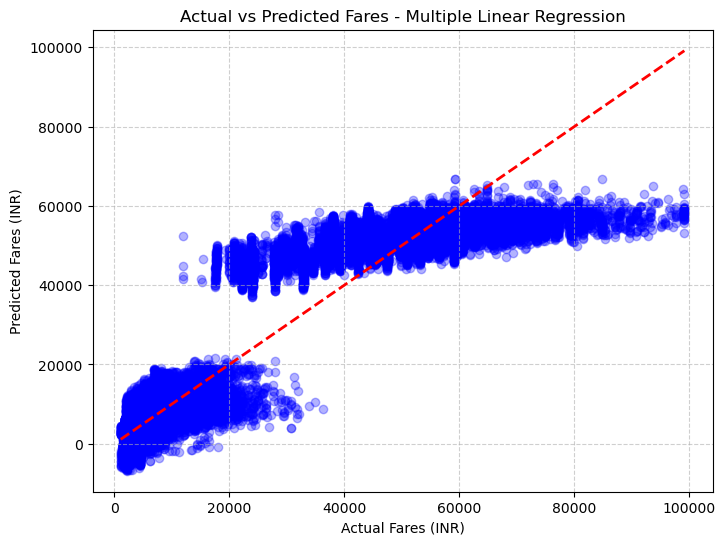

In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# Generate predictions for all three models
y_pred_slr = slr.predict(X_test_single)
y_pred_mlr = mlr.predict(X_test)
y_pred_poly = poly_reg.predict(X_test_poly)

# Function to calculate metrics
def evaluate_model(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    print(f"--- {model_name} ---")
    print(f"MAE:  {mae:.2f}")
    print(f"MSE:  {mse:.2f}")
    print(f"RMSE: {rmse:.2f}")
    print(f"R²:   {r2:.4f}\n")
    return {'Model': model_name, 'MAE': mae, 'RMSE': rmse, 'R² Score': r2}

# Evaluate all three
results = []
results.append(evaluate_model(y_test, y_pred_slr, "Simple Linear Regression"))
results.append(evaluate_model(y_test, y_pred_mlr, "Multiple Linear Regression"))
results.append(evaluate_model(y_test, y_pred_poly, "Polynomial Regression"))

# Create and display the Comparison Table (Fixed key to 'R² Score')
comparison_df = pd.DataFrame(results)
comparison_df = comparison_df.sort_values(by='R² Score', ascending=False).reset_index(drop=True)
comparison_df['Rank'] = comparison_df.index + 1
display(comparison_df)

# Plot Actual vs Predicted for Multiple Linear Regression (Best model with R² = 0.9105)
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_mlr, alpha=0.3, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Actual Fares (INR)")
plt.ylabel("Predicted Fares (INR)")
plt.title("Actual vs Predicted Fares - Multiple Linear Regression")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

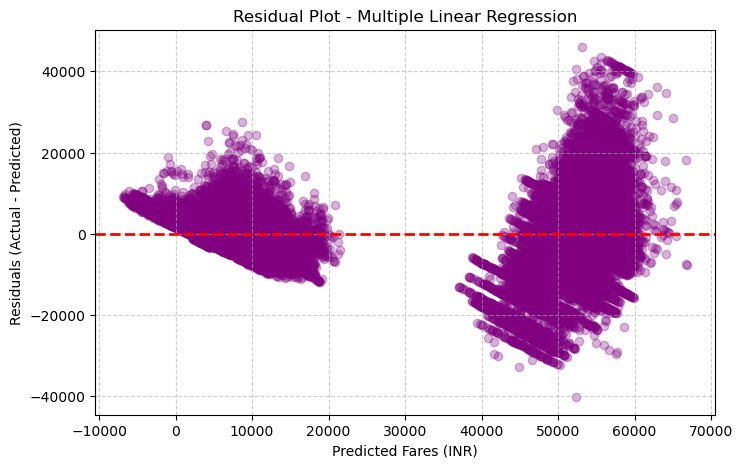

--- CAPSTONE 1 REPORT & FINDINGS ---
• Best Performing Model: Multiple Linear Regression (R² ≈ 0.9105)
• Effect of Class: Travel class (Economy vs Business) is one of the strongest cost drivers, with Business class substantially increasing fares.
• Effect of Days Left: Booking tickets closer to the departure date significantly drives up ticket prices due to surge pricing for last-minute travelers.


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Plot Residuals for Multiple Linear Regression
residuals = y_test - y_pred_mlr

plt.figure(figsize=(8, 5))
plt.scatter(y_pred_mlr, residuals, alpha=0.3, color='purple')
plt.axhline(y=0, color='r', linestyle='--', lw=2)
plt.xlabel("Predicted Fares (INR)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot - Multiple Linear Regression")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 2. Final Report Summary
print("--- CAPSTONE 1 REPORT & FINDINGS ---")
print("• Best Performing Model: Multiple Linear Regression (R² ≈ 0.9105)")
print("• Effect of Class: Travel class (Economy vs Business) is one of the strongest cost drivers, with Business class substantially increasing fares.")
print("• Effect of Days Left: Booking tickets closer to the departure date significantly drives up ticket prices due to surge pricing for last-minute travelers.")